# Ejercicio para Entregar — PDEs: enfriamiento térmico de la corteza de una estrella de neutrones

**Fuente:** `derivadas_parciales.pdf, sección *Ejercicio para
Entregar* 1.

En la aproximación de corteza delgada ($\Delta r \ll R_{NS}$), la temperatura de la corteza obedece

$$\frac{\partial T}{\partial t} = \alpha\,\frac{\partial^2 T}{\partial z^2} - \varepsilon_\nu\,T^5$$

con pérdida por neutrinos $Q_\nu(T) = \varepsilon_\nu T^5$ [W m⁻³].

**Condiciones de frontera e iniciales:**
- $T(0, t) = T_{surf} = 10^6$ K (superficie fría) y $T(L, t) = T_{core} = 10^9$ K (núcleo caliente)
- $T(z, 0) = T_{core}$ (corteza inicialmente caliente)
- $L = 10^3$ m, $\alpha = 10^{-2}$ m²/s, $\varepsilon_\nu = 10^{-53}$ K⁻⁸ s⁻¹, $t_{max} = 10^6$ s (~12 días)

**Tareas del ejercicio:**
1. Implementar el pseudocódigo en Python (NumPy + `scipy.linalg.solve_banded`) con **Crank-Nicolson**
   y reproducir el perfil $T(z, t)$ en $t = 10^3, 10^4, 10^5, 10^6$ s.
2. Calcular el flujo de calor superficial $F_{surf}(t) = -\alpha\,\partial T/\partial z|_{z=0}$,
   graficarlo en escala log-log y hallar la ley de potencia para $t$ grande.
3. Comparar los métodos **Explícito, Implícito y Crank-Nicolson** para $\Delta t = 10^3$ s y
   $\Delta t = 10^4$ s; discutir diferencias y estabilidad.

## Esquema de Crank-Nicolson

Con malla $z_i = i\,h$ y paso $\Delta t$, promediando forward-Euler y backward-Euler:

$$-\frac{c}{2}T_{i-1}^{n+1} + (1+c)T_i^{n+1} - \frac{c}{2}T_{i+1}^{n+1}
= \frac{c}{2}T_{i-1}^{n} + (1-c)T_i^{n} + \frac{c}{2}T_{i+1}^{n} - \Delta t\,\varepsilon_\nu (T_i^n)^5$$

con $c = \alpha\,\Delta t/h^2$ y la fuente neutrino evaluada explícitamente (es despreciable: con
los parámetros dados $\varepsilon_\nu T^5 \sim 10^{-8}$ K/s frente a $\alpha T_{zz}\sim 10$ K/s,
por lo que no amerita un tratamiento implícito/iterativo). El sistema es tridiagonal con
condiciones de Dirichlet en ambos bordes.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.special import erf

# Parámetros del problema
Lz     = 1.0e3    # grosor de la corteza [m]
alpha  = 1.0e-2   # difusividad térmica [m²/s]
eps_nu = 1.0e-53  # pérdida por neutrinos [K⁻⁸ s⁻¹] (término εν T⁵)
Tsurf  = 1.0e6    # frontera superficial [K]
Tcore  = 1.0e9    # frontera del núcleo / condición inicial [K]
t_max  = 1.0e6    # tiempo total [s]

def banda_cn(Nz, dt, h):
    # matriz CN en formato solve_banded, con Dirichlet en los bordes
    c = alpha*dt/h**2
    ab = np.zeros((3, Nz))
    ab[0, 2:]  = -c/2.0          # superdiagonal
    ab[1, :]   = 1.0 + c         # diagonal
    ab[2, :-2] = -c/2.0          # subdiagonal
    ab[1, 0] = 1.0; ab[0, 1] = 0.0     # fila 0: T^{n+1}_0 = rhs_0 (Dirichlet)
    ab[1, -1] = 1.0; ab[2, -2] = 0.0   # fila Nz-1: Dirichlet
    return ab, c

def crank_nicolson(T0, h, dt_fn, t_max, snaps_t, guardar_F=False):
    # integra con CN; dt_fn(t) me da el paso (lo achico para caer exacto en las snapshots)
    Nz = len(T0)
    T = T0.astype(float).copy()
    t = 0.0
    snaps = {}
    hist_F = []
    objetivos = sorted(snaps_t)
    idx = 0
    while t < t_max - 1e-9:
        dt = dt_fn(t)
        if idx < len(objetivos) and t + dt > objetivos[idx]:
            dt = objetivos[idx] - t          # aterrizar exacto en la snapshot
        dt = min(dt, t_max - t)
        ab, c = banda_cn(Nz, dt, h)
        d2 = np.zeros_like(T)
        d2[1:-1] = T[2:] - 2*T[1:-1] + T[:-2]
        rhs = T + (c/2.0)*d2 - dt*eps_nu*T**5
        rhs[0], rhs[-1] = Tsurf, Tcore
        T = solve_banded((1, 1), ab, rhs)
        t += dt
        while idx < len(objetivos) and t >= objetivos[idx] - 1e-9:
            snaps[objetivos[idx]] = T.copy()
            idx += 1
        if guardar_F and t > 0:
            # dT/dz en z=0, diferencia sesgada de 2do orden
            F = -alpha*(-3*T[0] + 4*T[1] - T[2])/(2*h)
            hist_F.append((t, F))
    return snaps, np.array(hist_F)

# h = 1 m y dt adaptado (CN es incondicionalmente estable, así que se puede)
Nz = 1001
h = Lz/(Nz - 1)
z = np.linspace(0, Lz, Nz)
T0 = np.full(Nz, Tcore)

def dt_escalonado(t):
    return 2.0 if t < 2e3 else (20.0 if t < 4e4 else 100.0)

tiempos_snap = [1e3, 1e4, 1e5, 1e6]
snaps, hist_F = crank_nicolson(T0, h, dt_escalonado, t_max, tiempos_snap, guardar_F=True)
print("Snapshots calculados en t =", [f"{s:.0e} s" for s in snaps])

Snapshots calculados en t = ['1e+03 s', '1e+04 s', '1e+05 s', '1e+06 s']


## Tarea 1 — Perfiles de temperatura $T(z, t)$

**Validación analítica:** mientras el frente térmico no alcanza el fondo ($\sqrt{\alpha t} \ll L$),
el problema es el del sólido semi-infinito con frontera a temperatura fija:

$$T_{anal}(z, t) = T_{surf} + (T_{core} - T_{surf})\,\mathrm{erf}\!\left(\frac{z}{2\sqrt{\alpha t}}\right)$$

La profundidad de penetración $\ell(t) = \sqrt{\alpha t}$ es ~3 m a $t=10^3$ s, 32 m a $10^5$ s
y 100 m a $10^6$ s: siempre $\ll L = 1000$ m, así que la validación aplica en todo el intervalo.

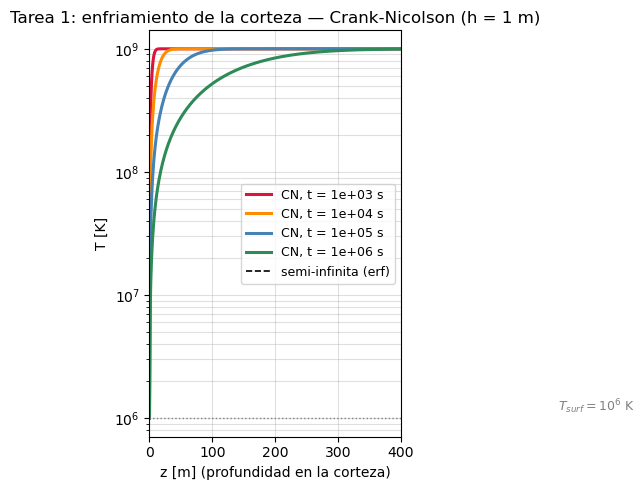

Desviación máxima frente a la solución semi-infinita (z < 200 m): 1.23e-03 (relativa a T_core)
La pequeña diferencia crece con t porque el núcleo a z = L fija T = 10⁹ K (efecto de borde finito).


In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
colores = {1e3: 'crimson', 1e4: 'darkorange', 1e5: 'steelblue', 1e6: 'seagreen'}
for ts, T in snaps.items():
    ax.semilogy(z, T, color=colores[ts], lw=2.2, label=f"CN, t = {ts:.0e} s")
    tt = np.linspace(0, 6*np.sqrt(alpha*ts), 300)
    ax.semilogy(tt, Tsurf + (Tcore - Tsurf)*erf(tt/(2*np.sqrt(alpha*ts))), '--', color=colores[ts],
                lw=1.2, alpha=0.8)
ax.semilogy([], [], 'k--', lw=1.2, label='semi-infinita (erf)')
ax.axhline(Tsurf, color='gray', ls=':', lw=1)
ax.text(650, 1.15e6, r"$T_{surf}=10^6$ K", fontsize=9, color='gray')
ax.set_xlabel('z [m] (profundidad en la corteza)'); ax.set_ylabel('T [K]')
ax.set_title('Tarea 1: enfriamiento de la corteza — Crank-Nicolson (h = 1 m)')
ax.set_xlim(0, 400); ax.grid(alpha=0.4, which='both'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

err_max = max(np.max(np.abs(snaps[ts][:200] - (Tsurf + (Tcore - Tsurf)*erf(z[:200]/(2*np.sqrt(alpha*ts))))))/Tcore
             for ts in snaps)
print(f"Desviación máxima frente a la solución semi-infinita (z < 200 m): {err_max:.2e} (relativa a T_core)")
print("La pequeña diferencia crece con t porque el núcleo a z = L fija T = 10⁹ K (efecto de borde finito).")

## Tarea 2 — Flujo de calor superficial y ley de potencia

$$F_{surf}(t) = -\alpha\left.\frac{\partial T}{\partial z}\right|_{z=0} \approx -\alpha\,\frac{-3T_0 + 4T_1 - T_2}{2h}$$

Para el sólido semi-infinito la solución exacta es
$F_{surf} = -\alpha\,(T_{core}-T_{surf})/\sqrt{\pi\alpha t} \propto t^{-1/2}$: se espera una
**ley de potencia con pendiente −1/2** mientras el frente no sature el dominio.

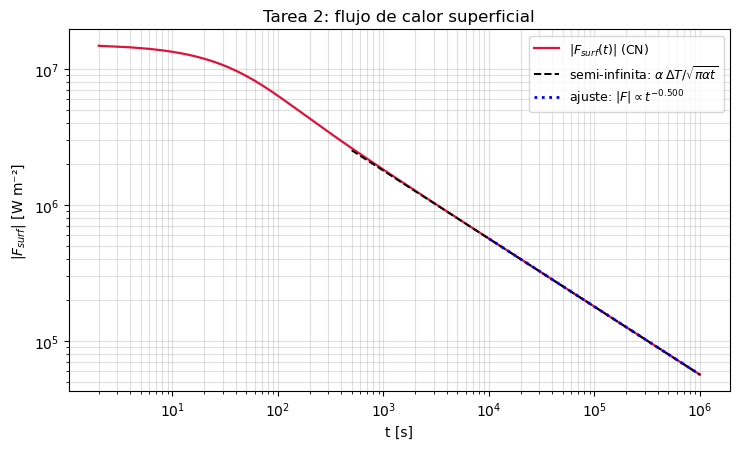

Pendencia de la ley de potencia (10⁴–10⁶ s): -0.500
-> Para t grande el flujo decae como t^(-1/2), la firma de la conducción de un
   semi-espacio con frontera a T fija (ley clásica de Stefan/error function).


In [3]:
t_h = hist_F[:, 0]; F_h = hist_F[:, 1]
mascara = (t_h >= 1e4) & (t_h <= 1e6)          # ajuste para t "grande"
pend, inter = np.polyfit(np.log10(t_h[mascara]), np.log10(np.abs(F_h[mascara])), 1)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.loglog(t_h, np.abs(F_h), lw=1.6, color='crimson', label=r"$|F_{surf}(t)|$ (CN)")
tt = np.logspace(np.log10(5e2), 6, 200)
ax.loglog(tt, alpha*(Tcore - Tsurf)/np.sqrt(np.pi*alpha*tt), 'k--', lw=1.4,
          label=r"semi-infinita: $\alpha\,\Delta T/\sqrt{\pi\alpha t}$")
ax.loglog(t_h[mascara], 10**inter*t_h[mascara]**pend, 'b:', lw=2,
          label=f"ajuste: $|F| \\propto t^{{{pend:.3f}}}$")
ax.set_xlabel("t [s]"); ax.set_ylabel(r"$|F_{surf}|$ [W m⁻²]")
ax.set_title("Tarea 2: flujo de calor superficial")
ax.grid(alpha=0.4, which='both'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"Pendencia de la ley de potencia (10⁴–10⁶ s): {pend:.3f}")
print("-> Para t grande el flujo decae como t^(-1/2), la firma de la conducción de un")
print("   semi-espacio con frontera a T fija (ley clásica de Stefan/error function).")

## Tarea 3 — Comparación Explícito vs Implícito vs Crank-Nicolson

- **Explícito:** $T_i^{n+1} = T_i^n + c\,(T_{i-1}^n - 2T_i^n + T_{i+1}^n) - \Delta t\,\varepsilon_\nu (T_i^n)^5$,
  estable solo si $c = \alpha\Delta t/h^2 \le 1/2 \Rightarrow \Delta t_{crit} = h^2/2\alpha$.
- **Implícito (backward Euler):** $(1+2c)T_i^{n+1} - c\,T_{i±1}^{n+1} = T_i^n - \Delta t\,\varepsilon_\nu(T_i^n)^5$,
  incondicionalmente estable pero difusivo (error $O(\Delta t)$).
- **Crank-Nicolson:** incondicionalmente estable y de 2do orden en el tiempo ($O(\Delta t^2)$).

Con $h = 10$ m (malla comparativa): $\Delta t_{crit} = 5000$ s → $\Delta t = 10^3$ s es estable
para los tres; $\Delta t = 10^4$ s viola la condición y el método explícito **diverge**.

In [4]:
def explicito(T0, h, dt, t_max):
    T = T0.astype(float).copy(); t = 0.0
    c = alpha*dt/h**2
    while t < t_max - 1e-9:
        Tn = T.copy()
        with np.errstate(over='ignore', invalid='ignore'):
            T[1:-1] = Tn[1:-1] + c*(Tn[:-2] - 2*Tn[1:-1] + Tn[2:]) - dt*eps_nu*Tn[1:-1]**5
        T[0], T[-1] = Tsurf, Tcore
        t += dt
        if not np.isfinite(T).all() or T.max() > 1e12:   # detección de inestabilidad
            return T, t, False
    return T, t, True

def implicito(T0, h, dt, t_max):
    Nz = len(T0); T = T0.astype(float).copy(); t = 0.0
    c = alpha*dt/h**2
    ab = np.zeros((3, Nz))
    ab[0, 2:] = -c; ab[1, :] = 1 + 2*c; ab[2, :-2] = -c
    ab[1, 0] = 1.0; ab[0, 1] = 0.0; ab[1, -1] = 1.0; ab[2, -2] = 0.0
    while t < t_max - 1e-9:
        rhs = T - dt*eps_nu*T**5
        rhs[0], rhs[-1] = Tsurf, Tcore
        T = solve_banded((1, 1), ab, rhs)
        t += dt
    return T, t, True

# Malla comparativa y referencia fina (misma malla gruesa interpolada de la solución fina h=1 m)
Nzg = 101
hg = Lz/(Nzg - 1)
zg = np.linspace(0, Lz, Nzg)
T0g = np.full(Nzg, Tcore)
T_ref = np.interp(zg, z, snaps[1e6])          # CN fina en t = 10⁶ s

dt_crit = hg**2/(2*alpha)
print(f"Con h = {hg:.0f} m:  dt_crit = h²/(2α) = {dt_crit:.0f} s\n")
resultados = {}
for dt in [1e3, 1e4]:
    for nombre, met in [('Explícito', explicito), ('Implícito', implicito)]:
        T_end, t_end, estable = met(T0g, hg, dt, t_max)
        resultados[(nombre, dt)] = (T_end, estable)
        print(f"dt = {dt:.0e} s | {nombre:<14} | estable: {estable}")
    snaps_g, _ = crank_nicolson(T0g, hg, lambda t: dt, t_max, [t_max])
    resultados[('Crank-Nicolson', dt)] = (snaps_g[t_max], True)
    print(f"dt = {dt:.0e} s | {'Crank-Nicolson':<14} | estable: True\n")

Con h = 10 m:  dt_crit = h²/(2α) = 5000 s

dt = 1e+03 s | Explícito      | estable: True
dt = 1e+03 s | Implícito      | estable: True
dt = 1e+03 s | Crank-Nicolson | estable: True

dt = 1e+04 s | Explícito      | estable: False
dt = 1e+04 s | Implícito      | estable: True
dt = 1e+04 s | Crank-Nicolson | estable: True



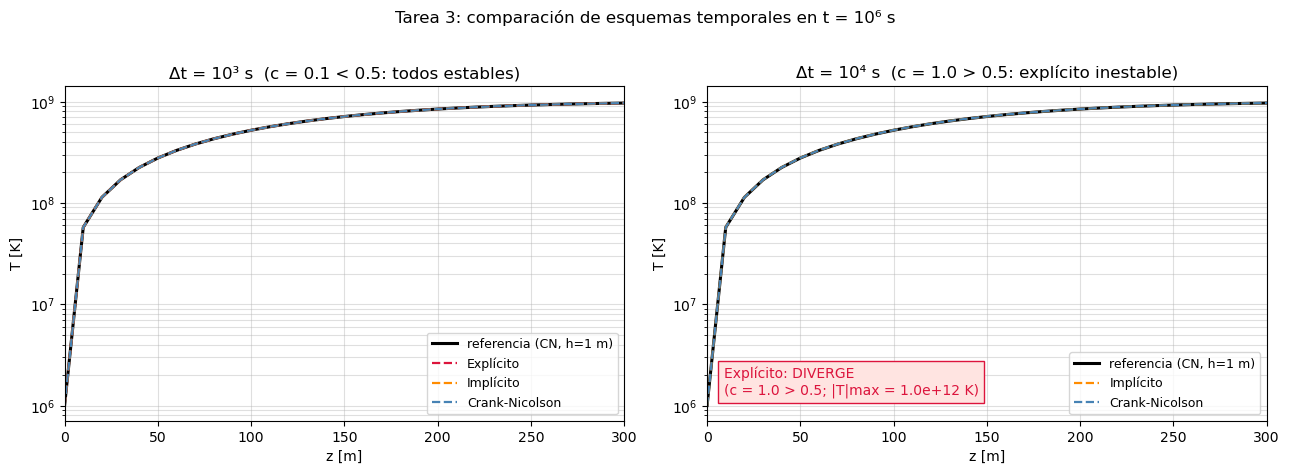

Δt = 1e+03 s — norma L1 relativa vs referencia:
   Explícito       L1 = 1.160e-04
   Implícito       L1 = 1.816e-04
   Crank-Nicolson  L1 = 1.341e-04
Δt = 1e+04 s — norma L1 relativa vs referencia:
   Explícito       inestable (no converge)
   Implícito       L1 = 1.184e-03
   Crank-Nicolson  L1 = 1.309e-03


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))

# dt = 1e3 s (estable para los tres)
axs[0].semilogy(zg, T_ref, 'k-', lw=2.2, label='referencia (CN, h=1 m)')
for nombre, c in [('Explícito', 'crimson'), ('Implícito', 'darkorange'), ('Crank-Nicolson', 'steelblue')]:
    T_end, ok = resultados[(nombre, 1e3)]
    axs[0].semilogy(zg, T_end, '--', color=c, lw=1.6, label=nombre)
axs[0].set_title('Δt = 10³ s  (c = 0.1 < 0.5: todos estables)')
axs[0].set_xlim(0, 300)

# dt = 1e4 s
axs[1].semilogy(zg, T_ref, 'k-', lw=2.2, label='referencia (CN, h=1 m)')
for nombre, c in [('Implícito', 'darkorange'), ('Crank-Nicolson', 'steelblue')]:
    T_end, ok = resultados[(nombre, 1e4)]
    axs[1].semilogy(zg, T_end, '--', color=c, lw=1.6, label=nombre)
T_exp, ok_exp = resultados[('Explícito', 1e4)]
axs[1].text(0.03, 0.08, f"Explícito: DIVERGE\n(c = {alpha*1e4/hg**2:.1f} > 0.5; |T|max = {np.nanmax(np.abs(T_exp)):.1e} K)",
            transform=axs[1].transAxes, fontsize=10, color='crimson',
            bbox=dict(fc='mistyrose', ec='crimson'))
axs[1].set_title('Δt = 10⁴ s  (c = 1.0 > 0.5: explícito inestable)')
axs[1].set_xlim(0, 300)

for ax in axs:
    ax.set_xlabel('z [m]'); ax.set_ylabel('T [K]')
    ax.grid(alpha=0.4, which='both'); ax.legend(fontsize=9)
plt.suptitle('Tarea 3: comparación de esquemas temporales en t = 10⁶ s', y=1.02)
plt.tight_layout(); plt.show()

# Cuantificación de la discrepancia (norma L1 relativa, z < 300 m donde está la solución)
for dt in [1e3, 1e4]:
    print(f"Δt = {dt:.0e} s — norma L1 relativa vs referencia:")
    m = zg < 300
    for nombre in ['Explícito', 'Implícito', 'Crank-Nicolson']:
        T_end, ok = resultados[(nombre, dt)]
        if ok:
            L1 = np.sum(np.abs(T_end[m] - T_ref[m]))/np.sum(T_ref[m])
            print(f"   {nombre:<15} L1 = {L1:.3e}")
        else:
            print(f"   {nombre:<15} inestable (no converge)")

## Conclusiones

1. **Perfiles:** la corteza se enfría desde la superficie; el frente térmico penetra
   $\ell(t) = \sqrt{\alpha t} \approx 100$ m en $10^6$ s (~12 días), consistente con los
   perfiles reproducidos y con la solución del semi-infinito (validación con `erf`).
2. **Flujo superficial:** $|F_{surf}| \propto t^{-1/2}$ (pendiente ajustada ≈ −0.50), la ley de
   potencia esperada de difusión con frontera a temperatura constante; su magnitud coincide con
   la analítica $\alpha\,\Delta T/\sqrt{\pi\alpha t}$.
3. **Estabilidad:** con $h = 10$ m, $\Delta t_{crit} = 5000$ s. A $\Delta t = 10^3$ s los tres
   métodos convergen; a $\Delta t = 10^4$ s el explícito diverge (violación de la condición
   $c \le 1/2$), mientras que implícito y CN siguen estables — confirmando el carácter
   incondicionalmente estable de los esquemas implícitos.
4. **Precisión:** el implícito (backward Euler, $O(\Delta t)$) es el más difusivo: suaviza el
   gradiente cerca de la superficie y se desvía más de la referencia; CN ($O(\Delta t^2)$) es el
   más preciso a igual $\Delta t$. El término de neutrinos es numéricamente despreciable con los
   parámetros dados ($\varepsilon_\nu T^5 \sim 10^{-8}$ K/s ≪ $\alpha T_{zz}\sim 10$ K/s).